# 🚗 License Plate Recognition — Training Pipeline
### Fine-tuning PP-OCRv5 vs PP-OCRv4 text recognition on European license plates

This notebook fine-tunes two PaddleOCR **text recognition** models on cropped license plates and compares them:

| Model | Architecture | Starting weights |
|---|---|---|
| `PP-OCRv5_server_rec` | PP-HGNetV2-B4 backbone, CTC + NRTR heads | official PP-OCRv5 pretrained weights |
| `PP-OCRv4_server_rec` | PP-HGNet backbone, CTC + NRTR heads | official PP-OCRv4 pretrained weights |

**How the pieces fit together.** A recognition model reads the characters in an image that is already cropped to a single text line.
The training data here is already cropped to the plate, so only the recognizer is trained.
In the inference notebook (`PPOCR_License_Plate_Inference.ipynb`), a pretrained PP-OCR **detection** model finds the plate in a full car photo and the fine-tuned recognizer from this notebook reads it.

```
Kaggle plates ──► label files (80/20 split) ──► configs ──► train v5 ─┐
                                                           train v4 ─┴─► curves ─► evaluation ─► export ─► comparison ─► Google Drive
```

**Before running**
1. `Runtime → Change runtime type → T4 GPU`.
2. Add your Kaggle API token as a Colab secret: key icon in the left sidebar → **Add new secret** → name `KAGGLE_API_TOKEN`, paste the token, enable *Notebook access*.
3. `Runtime → Run all`. You'll be asked once to authorize Google Drive; trained models are saved there for the inference notebook.

**Contents**
1. Setup · 2. Configuration · 3. Dataset · 4. Pretrained models · 5. Training configs · 6. Training · 7. Training curves · 8. Evaluation · 9. Export · 10. Comparison · 11. Save artifacts · 12. Findings

## 1. Setup
Install PaddlePaddle (GPU build) and PaddleOCR, and clone the PaddleOCR repository, which contains the training tools (`tools/train.py`, `tools/eval.py`, `tools/export_model.py`) and the model configs.
Versions are pinned so the notebook gives the same behaviour every time it runs.

In [1]:
import os, sys, re, json, time, random, shutil, subprocess, collections

IN_COLAB = "google.colab" in sys.modules
if os.name == "nt":
    # Windows: make the CUDA DLLs installed by pip (nvidia-* packages) visible to Paddle and its subprocesses.
    import site
    for sp in site.getsitepackages():
        nv = os.path.join(sp, "nvidia")
        if os.path.isdir(nv):
            bins = [os.path.join(nv, d, "bin") for d in os.listdir(nv) if os.path.isdir(os.path.join(nv, d, "bin"))]
            os.environ["PATH"] = os.pathsep.join(bins + [os.environ["PATH"]])
print("Running in Colab:", IN_COLAB, "| Python", sys.version.split()[0])
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv

Running in Colab: False | Python 3.11.15


name, memory.total [MiB], driver_version
NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144 MiB, 616.56


In [2]:
PADDLE_VERSION = "3.3.1"     # paddlepaddle-gpu, CUDA 12.6 build
PADDLEOCR_VERSION = "3.7.0"  # pip package (inference API) and git tag of the repo (training tools)

if IN_COLAB:
    # ~1-2 GB download from Paddle's server; can take 5-15 min on Colab (progress bar shown)
    !pip install paddlepaddle-gpu=={PADDLE_VERSION} -i https://www.paddlepaddle.org.cn/packages/stable/cu126/
    !pip install -q paddleocr=={PADDLEOCR_VERSION} kaggle python-dotenv

In [3]:
WORK_DIR = "/content/ppocr_lp" if IN_COLAB else os.path.abspath("work")
REPO_DIR = os.path.join(WORK_DIR, "PaddleOCR")
os.makedirs(WORK_DIR, exist_ok=True)

if not os.path.isdir(REPO_DIR):
    !git clone -q --depth 1 --branch v{PADDLEOCR_VERSION} https://github.com/PaddlePaddle/PaddleOCR.git {REPO_DIR}
if IN_COLAB:
    !pip install -q -r {REPO_DIR}/requirements.txt
print("PaddleOCR repo:", REPO_DIR)

PaddleOCR repo: C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\work\PaddleOCR


In [4]:
import paddle

print("paddle", paddle.__version__, "| compiled with CUDA:", paddle.device.is_compiled_with_cuda(),
      "| visible GPUs:", paddle.device.cuda.device_count())
paddle.utils.run_check()

paddle 3.3.1 | compiled with CUDA: True | visible GPUs: 1
Running verify PaddlePaddle program ... 


C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\.venv\Lib\site-packages\paddle\pir\math_op_patch.py:241: UserWarning: Tensor do not have 'place' interface for pir graph mode, try not to use it. None will be returned.
  warnings.warn(


PaddlePaddle works well on 1 GPU.
PaddlePaddle is installed successfully! Let's start deep learning with PaddlePaddle now.


In [5]:
# Google Drive holds the trained models so the inference notebook can load them.
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ARTIFACT_DIR = "/content/drive/MyDrive/ppocr_license_plate"
else:
    ARTIFACT_DIR = os.path.abspath("artifacts")
os.makedirs(ARTIFACT_DIR, exist_ok=True)
print("Artifacts will be saved to:", ARTIFACT_DIR)

Artifacts will be saved to: C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\artifacts


## 2. Configuration
All experiment settings live in this one cell.

- `MODEL_SIZE = "server"` trains the models named in the assignment (`PP-OCRv5_server_rec`, `PP-OCRv4_server_rec`). `"mobile"` is about 10× smaller and faster, but less accurate.
- The official configs use batch size 128 and train on millions of images. For about 530 plates we use a smaller batch and a much smaller learning rate, so fine-tuning adjusts the pretrained weights instead of overwriting them. A first run at 2e-4 overfitted: training accuracy reached 100% while validation accuracy dropped from 86% to about 80%.

In [6]:
MODEL_SIZE = "server"
EPOCHS = 40
BATCH_SIZE = 32
LEARNING_RATE = 5e-5
SEED = 42
NUM_WORKERS = 0 if os.name == "nt" else 2  # multi-process data loading is unreliable on Windows

DATA_DIR = os.path.join(WORK_DIR, "data")
PRETRAINED_DIR = os.path.join(WORK_DIR, "pretrained")
CONFIG_DIR = os.path.join(WORK_DIR, "configs")
OUTPUT_DIR = os.path.join(WORK_DIR, "output")
INFERENCE_DIR = os.path.join(WORK_DIR, "inference")
RESULTS_DIR = os.path.join(WORK_DIR, "results")
for d in (DATA_DIR, PRETRAINED_DIR, CONFIG_DIR, OUTPUT_DIR, INFERENCE_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

PRETRAINED_URL = "https://paddle-model-ecology.bj.bcebos.com/paddlex/official_pretrained_model/{}_pretrained.pdparams"
MODELS = {
    "PP-OCRv5": {"name": f"PP-OCRv5_{MODEL_SIZE}_rec", "base_config": f"configs/rec/PP-OCRv5/PP-OCRv5_{MODEL_SIZE}_rec.yml"},
    "PP-OCRv4": {"name": f"PP-OCRv4_{MODEL_SIZE}_rec", "base_config": f"configs/rec/PP-OCRv4/PP-OCRv4_{MODEL_SIZE}_rec.yml"},
}
for m in MODELS.values():
    m["pretrained"] = os.path.join(PRETRAINED_DIR, f"{m['name']}_pretrained.pdparams")
    m["config"] = os.path.join(CONFIG_DIR, f"{m['name']}_license_plate.yml")
    m["save_dir"] = os.path.join(OUTPUT_DIR, m["name"])
    m["inference_dir"] = os.path.join(INFERENCE_DIR, m["name"])

random.seed(SEED)
print(json.dumps({k: v["name"] for k, v in MODELS.items()}, indent=2))

{
  "PP-OCRv5": "PP-OCRv5_server_rec",
  "PP-OCRv4": "PP-OCRv4_server_rec"
}


## 3. Dataset

### Source
| | |
|---|---|
| **Dataset** | [European License Plates Dataset](https://www.kaggle.com/datasets/abdelhamidzakaria/european-license-plates-dataset) (Kaggle, MIT license) |
| **Content** | 735 photos of license plates, already cropped to the plate, from several European countries |
| **Labels** | The file name is the plate number, e.g. `04WH3753.png` → `04WH3753` |

### Collection & preparation methodology
1. **Download** the dataset with the Kaggle API, authenticated with the token stored as a Colab secret.
2. **Label extraction:** take the label from the file name. Suffixes such as `_1` and `_2` mark extra photos of the same plate (e.g. `381ATK83_1.png`), so they are stripped. Labels are checked to contain only `A–Z` and `0–9`.
3. **80/20 split by plate:** the dataset's original *train* and *val* folders are merged and re-split 80/20. The split is done **by plate number, not by image**, so photos of the same plate never end up in both training and validation. Kaggle's original split has 9 plates in both folders, which would inflate validation accuracy.
4. **Held-out test set:** the original *test* folder is kept for the inference notebook. Test images whose plate also appears in train/val are removed so the test set is truly unseen.
5. **Format:** PaddleOCR recognition format, one image per line: `relative/path.png<TAB>LABEL`.

In [7]:
# Kaggle credentials: Colab secret KAGGLE_API_TOKEN, or a .env file next to the notebook when running locally.
if IN_COLAB:
    from google.colab import userdata
    try:
        os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    except Exception as e:
        raise RuntimeError("Add your Kaggle token as a Colab secret named KAGGLE_API_TOKEN "
                           "(key icon in the left sidebar) and enable notebook access.") from e
else:
    from dotenv import load_dotenv
    load_dotenv(".env")

from kaggle.api.kaggle_api_extended import KaggleApi

kaggle_api = KaggleApi()
kaggle_api.authenticate()

RAW_DIR = os.path.join(DATA_DIR, "raw", "eu_plates")
if not os.path.isdir(RAW_DIR):
    kaggle_api.dataset_download_files("abdelhamidzakaria/european-license-plates-dataset", path=RAW_DIR, unzip=True)
PLATES_ROOT = os.path.join(RAW_DIR, "dataset_final")
for split in ("train", "val", "test"):
    print(f"{split:5s}: {len(os.listdir(os.path.join(PLATES_ROOT, split)))} images")

train: 588 images
val  : 74 images
test : 73 images


In [8]:
from pathlib import Path
import pandas as pd

IMAGE_EXTS = {".png", ".jpg", ".jpeg"}

def plate_label(path):
    """The file name is the plate number; '_1', '_2', ... mark extra photos of the same plate."""
    return re.sub(r"_\d+$", "", Path(path).stem).upper()

def collect(split):
    items = []
    for p in sorted(Path(PLATES_ROOT, split).iterdir()):
        if p.suffix.lower() in IMAGE_EXTS:
            label = plate_label(p)
            assert re.fullmatch(r"[A-Z0-9]+", label), f"unexpected label {label!r} in {p}"
            items.append((f"{split}/{p.name}", label))
    return items

pool = collect("train") + collect("val")
test_items = collect("test")

# 80/20 split by plate number so the same plate never appears in both train and val.
plates = sorted({label for _, label in pool})
random.Random(SEED).shuffle(plates)
val_plates = set(plates[: round(0.2 * len(plates))])
train_items = [it for it in pool if it[1] not in val_plates]
val_items = [it for it in pool if it[1] in val_plates]

# Keep the test set truly unseen.
seen = {label for _, label in pool}
leaked = [it for it in test_items if it[1] in seen]
test_items = [it for it in test_items if it[1] not in seen]

SPLITS = {"train": train_items, "val": val_items, "test": test_items}
LABEL_FILES = {}
for name, items in SPLITS.items():
    LABEL_FILES[name] = os.path.join(DATA_DIR, f"{name}.txt")
    with open(LABEL_FILES[name], "w", encoding="utf-8") as f:
        f.writelines(f"{img}\t{label}\n" for img, label in items)

total = len(train_items) + len(val_items)
display(pd.DataFrame([
    {"split": n, "images": len(it), "unique plates": len({l for _, l in it}),
     "share of train+val": f"{len(it) / total:.0%}" if n != "test" else "held out"}
    for n, it in SPLITS.items()]))
print(f"Removed {len(leaked)} test images whose plate also appears in train/val.")
print("Example label lines:")
print(open(LABEL_FILES["train"], encoding="utf-8").read().splitlines()[:3])

,split,images,unique plates,share of train+val
0,train,530,502,80%
1,val,132,125,20%
2,test,67,67,held out


Removed 6 test images whose plate also appears in train/val.
Example label lines:
['train/00LH2877.png\t00LH2877', 'train/0310CRG.png\t0310CRG', 'train/04KY53I2.png\t04KY53I2']


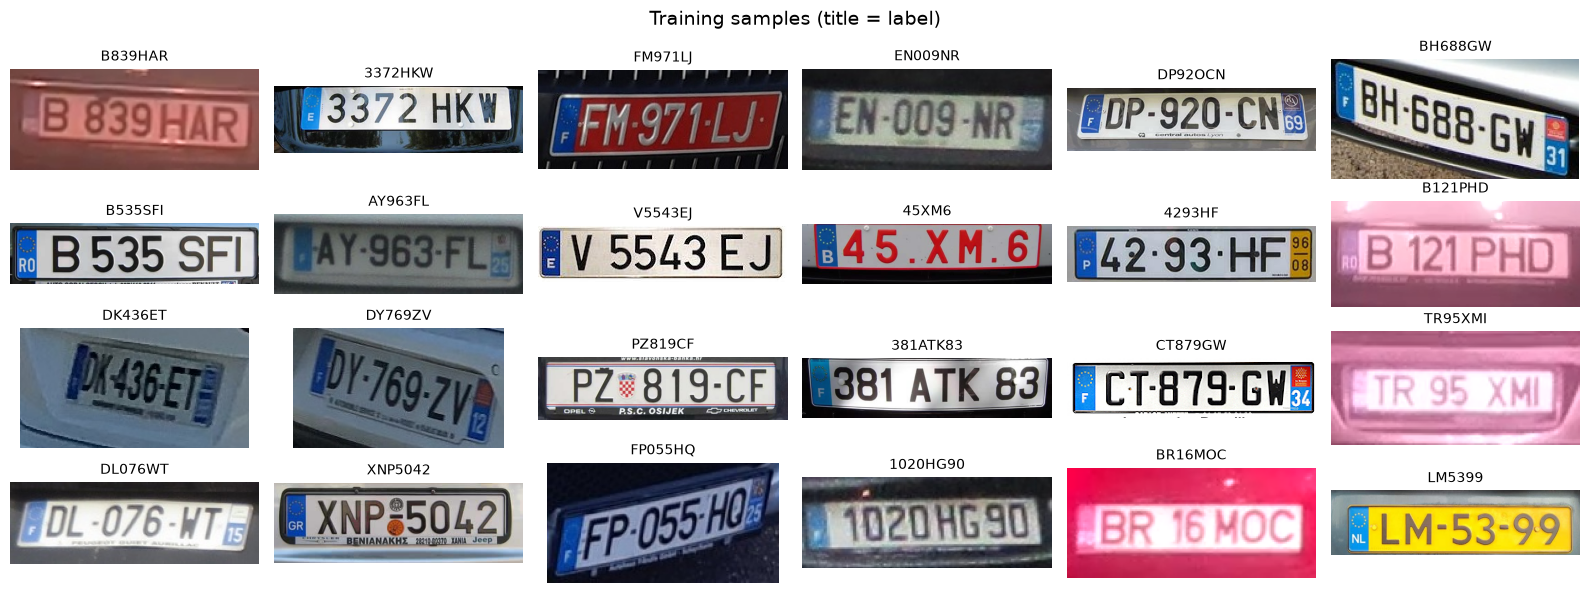

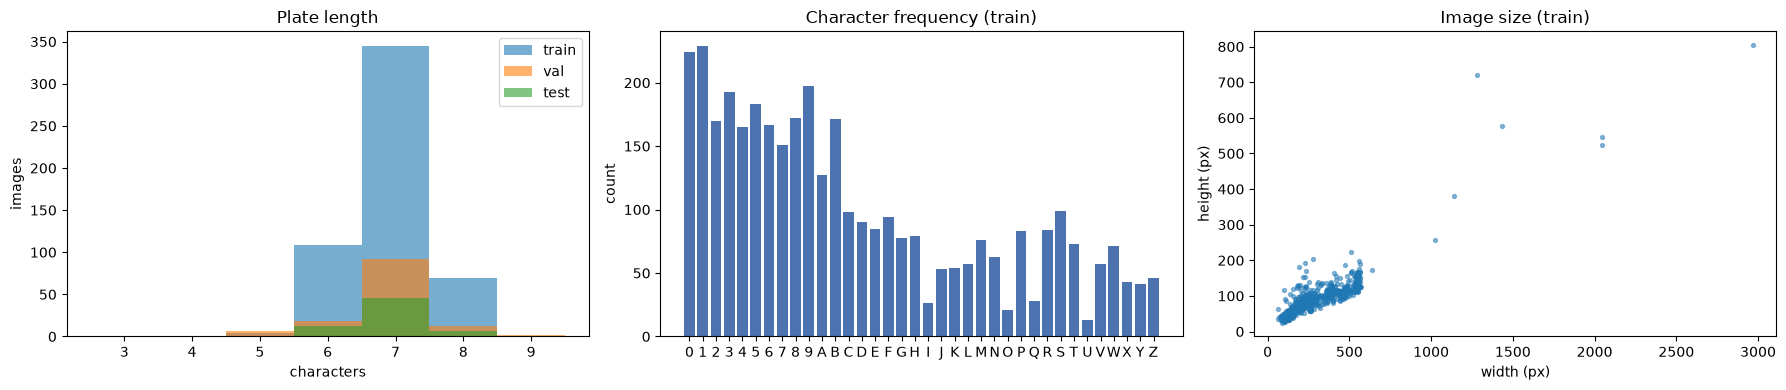

In [9]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(4, 6, figsize=(16, 6))
for ax, (img, label) in zip(axes.flat, random.Random(SEED).sample(train_items, 24)):
    ax.imshow(Image.open(os.path.join(PLATES_ROOT, img)).convert("RGB"))
    ax.set_title(label, fontsize=10)
    ax.axis("off")
fig.suptitle("Training samples (title = label)", fontsize=14)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for name, items in SPLITS.items():
    axes[0].hist([len(l) for _, l in items], bins=range(3, 11), alpha=0.6, label=name, align="left")
axes[0].set(title="Plate length", xlabel="characters", ylabel="images")
axes[0].legend()
chars = collections.Counter("".join(l for _, l in train_items))
keys = sorted(chars)
axes[1].bar(keys, [chars[k] for k in keys], color="#4c72b0")
axes[1].set(title="Character frequency (train)", ylabel="count")
sizes = [Image.open(os.path.join(PLATES_ROOT, img)).size for img, _ in train_items]
axes[2].scatter(*zip(*sizes), s=8, alpha=0.5)
axes[2].set(title="Image size (train)", xlabel="width (px)", ylabel="height (px)")
plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "dataset_overview.png"), dpi=120)
plt.show()

## 4. Pretrained models
Download the official pretrained weights for `PP-OCRv5_server_rec` and `PP-OCRv4_server_rec`. Fine-tuning starts from these weights instead of from random ones, which is what makes training on a few hundred images possible.

In [10]:
import urllib.request

for key, m in MODELS.items():
    if not os.path.exists(m["pretrained"]):
        urllib.request.urlretrieve(PRETRAINED_URL.format(m["name"]), m["pretrained"])
    print(f"{key}: {os.path.basename(m['pretrained'])} ({os.path.getsize(m['pretrained']) / 1e6:.0f} MB)")

PP-OCRv5: PP-OCRv5_server_rec_pretrained.pdparams (215 MB)
PP-OCRv4: PP-OCRv4_server_rec_pretrained.pdparams (158 MB)


## 5. Training configs
Each model starts from its official config in the PaddleOCR repo. Only these settings are changed:

| Setting | Official | Here | Why |
|---|---|---|---|
| `Global.pretrained_model` | empty | official weights | fine-tune instead of training from scratch |
| `Global.epoch_num` | 75 / 200 | 40 | validation accuracy stops improving well before this |
| `Global.eval_batch_step` | every 2000 steps | about every 2 epochs | an epoch is only ~17 steps here |
| `Train.sampler.first_bs`, `batch_size_per_card` | 128 | 32 | fewer images, and fits a T4 GPU |
| `Optimizer.lr.learning_rate` | 5e-4 | 5e-5 | at 2e-4 the models memorised the 530 training plates (100% train vs ~80% val accuracy), so a 10× smaller rate is used |
| dataset paths | `./train_data/...` | our label files | |

The character dictionary is **kept unchanged**. Plates only use `A–Z0–9`, which both official dictionaries already contain, so the pretrained output layer is reused as-is.

In [11]:
import yaml

STEPS_PER_EPOCH = max(1, len(train_items) // BATCH_SIZE)
EVAL_EVERY = 2 * STEPS_PER_EPOCH

def build_config(m):
    with open(os.path.join(REPO_DIR, m["base_config"]), encoding="utf-8") as f:
        cfg = yaml.safe_load(f)
    cfg["Global"].update({
        "epoch_num": EPOCHS,
        "print_batch_step": 5,
        "save_epoch_step": EPOCHS + 1,  # keep only latest + best checkpoints
        "eval_batch_step": [0, EVAL_EVERY],
        "save_model_dir": m["save_dir"],
        "pretrained_model": m["pretrained"],
        "save_res_path": os.path.join(m["save_dir"], "predicts.txt"),
        "distributed": False,
        "use_visualdl": False,
    })
    cfg["Optimizer"]["lr"].update({"learning_rate": LEARNING_RATE, "warmup_epoch": 1})
    for section, split in (("Train", "train"), ("Eval", "val")):
        cfg[section]["dataset"]["data_dir"] = PLATES_ROOT
        cfg[section]["dataset"]["label_file_list"] = [LABEL_FILES[split]]
        cfg[section]["loader"]["num_workers"] = NUM_WORKERS
    cfg["Train"]["loader"]["batch_size_per_card"] = BATCH_SIZE
    if "sampler" in cfg["Train"]:
        cfg["Train"]["sampler"]["first_bs"] = BATCH_SIZE
    cfg["Eval"]["loader"]["batch_size_per_card"] = 64
    with open(m["config"], "w", encoding="utf-8") as f:
        yaml.safe_dump(cfg, f, sort_keys=False, allow_unicode=True)
    return cfg

configs = {key: build_config(m) for key, m in MODELS.items()}
display(pd.DataFrame({
    key: {
        "algorithm": c["Architecture"]["algorithm"],
        "backbone": c["Architecture"]["Backbone"]["name"],
        "dictionary": os.path.basename(c["Global"]["character_dict_path"]),
        "epochs": c["Global"]["epoch_num"],
        "batch size": c["Train"]["loader"]["batch_size_per_card"],
        "learning rate": c["Optimizer"]["lr"]["learning_rate"],
        "eval every (steps)": c["Global"]["eval_batch_step"][1],
    } for key, c in configs.items()}))

,PP-OCRv5,PP-OCRv4
algorithm,SVTR_HGNet,SVTR_HGNet
backbone,PPHGNetV2_B4,PPHGNet_small
dictionary,ppocrv5_dict.txt,ppocr_keys_v1.txt
epochs,40,40
batch size,32,32
learning rate,0.00005,0.00005
eval every (steps),32,32


## 6. Training
`tools/train.py` runs as a subprocess from the repo root. The full log is saved to `results/<model>_train.log`. Only the validation results and every 10th epoch are printed here, to keep the notebook readable.
The best checkpoint by validation accuracy is saved as `output/<model>/best_accuracy.pdparams`.

In [12]:
def run(cmd, log_path, show=lambda line: True):
    """Run a PaddleOCR tool from the repo root, print selected lines, keep the full log."""
    print("$", " ".join(os.path.relpath(c, REPO_DIR) if os.path.isabs(c) else c for c in cmd))
    tail = collections.deque(maxlen=40)
    with open(log_path, "w", encoding="utf-8") as log, subprocess.Popen(
        cmd, cwd=REPO_DIR, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1
    ) as proc:
        for line in proc.stdout:
            log.write(line)
            tail.append(line)
            if show(line):
                print(line.rstrip())
    if proc.returncode != 0:
        print("----- last lines of the log -----")
        print("".join(tail))
        raise RuntimeError(f"Command failed (exit code {proc.returncode}). Full log: {log_path}")

def training_progress():
    """Print validation results and one line every 10 epochs."""
    shown = set()
    def show(line):
        if "best metric" in line or "Error" in line or "Traceback" in line:
            return True
        epoch = re.search(r"epoch: \[(\d+)/", line)
        if epoch and int(epoch.group(1)) % 10 == 0 and epoch.group(1) not in shown:
            shown.add(epoch.group(1))
            return True
        return False
    return show

def train(key):
    m = MODELS[key]
    m["train_log"] = os.path.join(RESULTS_DIR, f"{m['name']}_train.log")
    start = time.time()
    run([sys.executable, "tools/train.py", "-c", m["config"]], m["train_log"], show=training_progress())
    m["train_minutes"] = (time.time() - start) / 60
    print(f"\n✅ {key} trained in {m['train_minutes']:.1f} min")

### 6.1 Train PP-OCRv5

In [13]:
train("PP-OCRv5")

$ ..\..\.venv\Scripts\python.exe tools/train.py -c ..\configs\PP-OCRv5_server_rec_license_plate.yml


[2026/10/25 20:57:32] ppocr INFO: best metric, acc: 0.7187499438476607, is_float16: False, norm_edit_dis: 0.9201109933445033, fps: 270.96067400135564, best_epoch: 2


[2026/10/25 20:57:47] ppocr INFO: best metric, acc: 0.8124999365234424, is_float16: False, norm_edit_dis: 0.9463541708577471, fps: 281.29028120597235, best_epoch: 3


[2026/10/25 20:58:03] ppocr INFO: best metric, acc: 0.8671874322509818, is_float16: False, norm_edit_dis: 0.9645182319386798, fps: 282.4563044990272, best_epoch: 5


[2026/10/25 20:58:18] ppocr INFO: best metric, acc: 0.8671874322509818, is_float16: False, norm_edit_dis: 0.9645182319386798, fps: 282.4563044990272, best_epoch: 5


...

[2026/10/25 21:04:05] ppocr INFO: best metric, acc: 0.8749999316406303, is_float16: False, norm_edit_dis: 0.9678664459628149, fps: 279.67416220834224, best_epoch: 35


[2026/10/25 21:04:19] ppocr INFO: best metric, acc: 0.8749999316406303, is_float16: False, norm_edit_dis: 0.9678664459628149, fps: 279.67416220834224, best_epoch: 35


[2026/10/25 21:04:21] ppocr INFO: epoch: [40/40], global_step: 900, lr: 0.000001, acc: 0.952380, norm_edit_dis: 0.993197, CTCLoss: 0.124045, NRTRLoss: 1.313084, loss: 1.437701, avg_reader_cost: 0.05811 s, avg_batch_cost: 0.42202 s, avg_samples: 21.2, ips: 50.23472 samples/s, eta: 0:00:08, max_mem_reserved: 5748 MB, max_mem_allocated: 3642 MB


[2026/10/25 21:04:30] ppocr INFO: best metric, acc: 0.8749999316406303, is_float16: False, norm_edit_dis: 0.9678664459628149, fps: 279.67416220834224, best_epoch: 35



✅ PP-OCRv5 trained in 7.4 min


### 6.2 Train PP-OCRv4

In [14]:
train("PP-OCRv4")

$ ..\..\.venv\Scripts\python.exe tools/train.py -c ..\configs\PP-OCRv4_server_rec_license_plate.yml


[2026/10/25 21:04:50] ppocr INFO: best metric, acc: 0.7734374395752001, is_float16: False, norm_edit_dis: 0.9420417952025879, fps: 222.76098845015676, best_epoch: 2


[2026/10/25 21:05:05] ppocr INFO: best metric, acc: 0.8437499340820364, is_float16: False, norm_edit_dis: 0.9581008217257543, fps: 222.14278733340976, best_epoch: 3


[2026/10/25 21:05:21] ppocr INFO: best metric, acc: 0.8593749328613334, is_float16: False, norm_edit_dis: 0.9615575426858567, fps: 224.42118727706628, best_epoch: 5


[2026/10/25 21:05:36] ppocr INFO: best metric, acc: 0.8671874322509818, is_float16: False, norm_edit_dis: 0.9624255981735954, fps: 224.56856865231063, best_epoch: 6


...

[2026/10/25 21:19:15] ppocr INFO: best metric, acc: 0.8906249304199273, is_float16: False, norm_edit_dis: 0.9678354439811099, fps: 224.7673232818226, best_epoch: 31


[2026/10/25 21:19:30] ppocr INFO: best metric, acc: 0.8906249304199273, is_float16: False, norm_edit_dis: 0.9678354439811099, fps: 229.0732301758144, best_epoch: 39


[2026/10/25 21:19:33] ppocr INFO: epoch: [40/40], global_step: 900, lr: 0.000001, acc: 0.874999, norm_edit_dis: 0.976403, CTCLoss: 1.179229, NRTRLoss: 1.229457, loss: 2.416200, avg_reader_cost: 0.02029 s, avg_batch_cost: 0.40937 s, avg_samples: 22.2, ips: 54.23018 samples/s, eta: 0:00:19, max_mem_reserved: 3981 MB, max_mem_allocated: 2782 MB


[2026/10/25 21:19:41] ppocr INFO: best metric, acc: 0.8906249304199273, is_float16: False, norm_edit_dis: 0.9678354439811099, fps: 229.0732301758144, best_epoch: 39



✅ PP-OCRv4 trained in 15.2 min


## 7. Training curves
The curves come from the training logs:
- **Training loss and accuracy** are logged every 5 steps, smoothed over a 20-step window.
- **Validation accuracy** is the share of plates read exactly right.
- **Normalized edit distance** is character-level similarity: 1.0 means every character is correct.

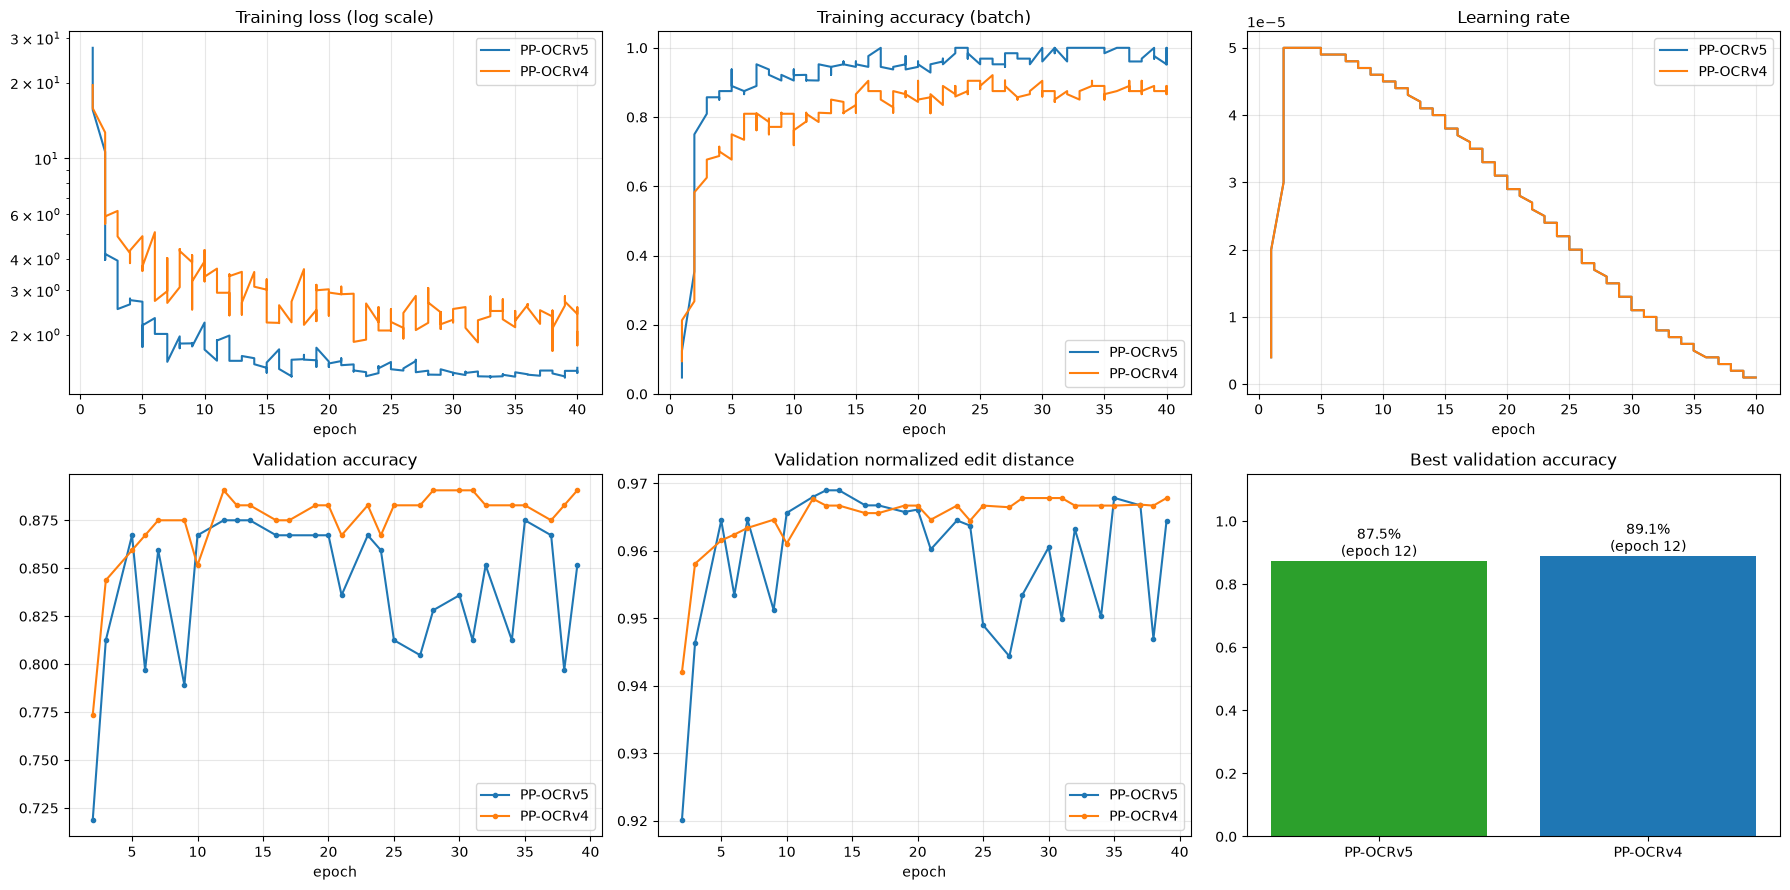

In [15]:
METRIC = re.compile(r"\b(lr|acc|norm_edit_dis|loss): ([-\d.e]+)")

def parse_train_log(path):
    train_rows, eval_rows, epoch, step = [], [], 0, 0
    with open(path, encoding="utf-8", errors="ignore") as f:
        for line in f:
            progress = re.search(r"epoch: \[(\d+)/\d+\], global_step: (\d+)", line)
            if progress:
                epoch, step = int(progress.group(1)), int(progress.group(2))
                train_rows.append({"epoch": epoch, "step": step, **{k: float(v) for k, v in METRIC.findall(line)}})
            elif "cur metric" in line:
                eval_rows.append({"epoch": epoch, "step": step, **{k: float(v) for k, v in METRIC.findall(line)}})
    return pd.DataFrame(train_rows), pd.DataFrame(eval_rows)

curves = {key: parse_train_log(m["train_log"]) for key, m in MODELS.items()}

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for key, (tr, ev) in curves.items():
    axes[0, 0].plot(tr["epoch"], tr["loss"], label=key)
    axes[0, 1].plot(tr["epoch"], tr["acc"], label=key)
    axes[0, 2].plot(tr["epoch"], tr["lr"], label=key)
    axes[1, 0].plot(ev["epoch"], ev["acc"], marker="o", ms=3, label=key)
    axes[1, 1].plot(ev["epoch"], ev["norm_edit_dis"], marker="o", ms=3, label=key)
axes[0, 0].set_yscale("log")
for ax, title in zip(axes.flat, ["Training loss (log scale)", "Training accuracy (batch)", "Learning rate",
                                 "Validation accuracy", "Validation normalized edit distance"]):
    ax.set(title=title, xlabel="epoch")
    ax.grid(alpha=0.3)
    ax.legend()

best = {key: ev.loc[ev["acc"].idxmax()] for key, (_, ev) in curves.items()}
bars = axes[1, 2].bar(list(best), [b["acc"] for b in best.values()], color=["#2ca02c", "#1f77b4"])
axes[1, 2].bar_label(bars, labels=[f"{b['acc']:.1%}\n(epoch {int(b['epoch'])})" for b in best.values()])
axes[1, 2].set(title="Best validation accuracy", ylim=(0, 1.15))
plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "training_curves.png"), dpi=120)
plt.show()

## 8. Evaluation
`tools/eval.py` evaluates each model on the **validation** set and the **held-out test** set, using two sets of weights:
- **zero-shot:** the official pretrained weights, before any fine-tuning. This is the baseline.
- **fine-tuned:** the best checkpoint from training.

The difference between the two shows what fine-tuning on plates achieved.

In [16]:
def evaluate(key, weights, split):
    m = MODELS[key]
    log_path = os.path.join(RESULTS_DIR, f"{m['name']}_eval_{split}_{os.path.basename(weights)}.log")
    run([sys.executable, "tools/eval.py", "-c", m["config"], "-o",
         f"Global.pretrained_model={weights}",
         f"Eval.dataset.label_file_list=['{LABEL_FILES[split]}']"],
        log_path, show=lambda line: "Error" in line)
    report = open(log_path, encoding="utf-8", errors="ignore").read().split("metric eval")[-1]
    return {k: float(v) for k, v in re.findall(r"\b(acc|norm_edit_dis|fps):\s*([\d.]+)", report)}

eval_rows = []
for key, m in MODELS.items():
    weights = {"zero-shot": m["pretrained"], "fine-tuned": os.path.join(m["save_dir"], "best_accuracy")}
    for variant, path in weights.items():
        for split in ("val", "test"):
            eval_rows.append({"model": key, "weights": variant, "split": split, **evaluate(key, path, split)})
eval_df = pd.DataFrame(eval_rows)
eval_df.to_csv(os.path.join(RESULTS_DIR, "evaluation.csv"), index=False)
display(eval_df.pivot_table(index=["model", "weights"], columns="split", values=["acc", "norm_edit_dis"])
        .style.format("{:.1%}").background_gradient(cmap="Greens", vmin=0, vmax=1))

$ ..\..\.venv\Scripts\python.exe tools/eval.py -c ..\configs\PP-OCRv5_server_rec_license_plate.yml -o Global.pretrained_model=C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\work\pretrained\PP-OCRv5_server_rec_pretrained.pdparams Eval.dataset.label_file_list=['C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\work\data\val.txt']


$ ..\..\.venv\Scripts\python.exe tools/eval.py -c ..\configs\PP-OCRv5_server_rec_license_plate.yml -o Global.pretrained_model=C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\work\pretrained\PP-OCRv5_server_rec_pretrained.pdparams Eval.dataset.label_file_list=['C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\work\data\test.txt']


$ ..\..\.venv\Scripts\python.exe tools/eval.py -c ..\configs\PP-OCRv5_server_rec_license_plate.yml -o Global.pretrained_model=C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\work\output\PP-OCRv5_server_rec\best_accuracy Eval.dataset.label_file_list=['C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\work\data\val.txt']


$ ..\..\.venv\Scripts\python.exe tools/eval.py -c ..\configs\PP-OCRv5_server_rec_license_plate.yml -o Global.pretrained_model=C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\work\output\PP-OCRv5_server_rec\best_accuracy Eval.dataset.label_file_list=['C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\work\data\test.txt']


$ ..\..\.venv\Scripts\python.exe tools/eval.py -c ..\configs\PP-OCRv4_server_rec_license_plate.yml -o Global.pretrained_model=C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\work\pretrained\PP-OCRv4_server_rec_pretrained.pdparams Eval.dataset.label_file_list=['C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\work\data\val.txt']


$ ..\..\.venv\Scripts\python.exe tools/eval.py -c ..\configs\PP-OCRv4_server_rec_license_plate.yml -o Global.pretrained_model=C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\work\pretrained\PP-OCRv4_server_rec_pretrained.pdparams Eval.dataset.label_file_list=['C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\work\data\test.txt']


$ ..\..\.venv\Scripts\python.exe tools/eval.py -c ..\configs\PP-OCRv4_server_rec_license_plate.yml -o Global.pretrained_model=C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\work\output\PP-OCRv4_server_rec\best_accuracy Eval.dataset.label_file_list=['C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\work\data\val.txt']


$ ..\..\.venv\Scripts\python.exe tools/eval.py -c ..\configs\PP-OCRv4_server_rec_license_plate.yml -o Global.pretrained_model=C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\work\output\PP-OCRv4_server_rec\best_accuracy Eval.dataset.label_file_list=['C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\work\data\test.txt']


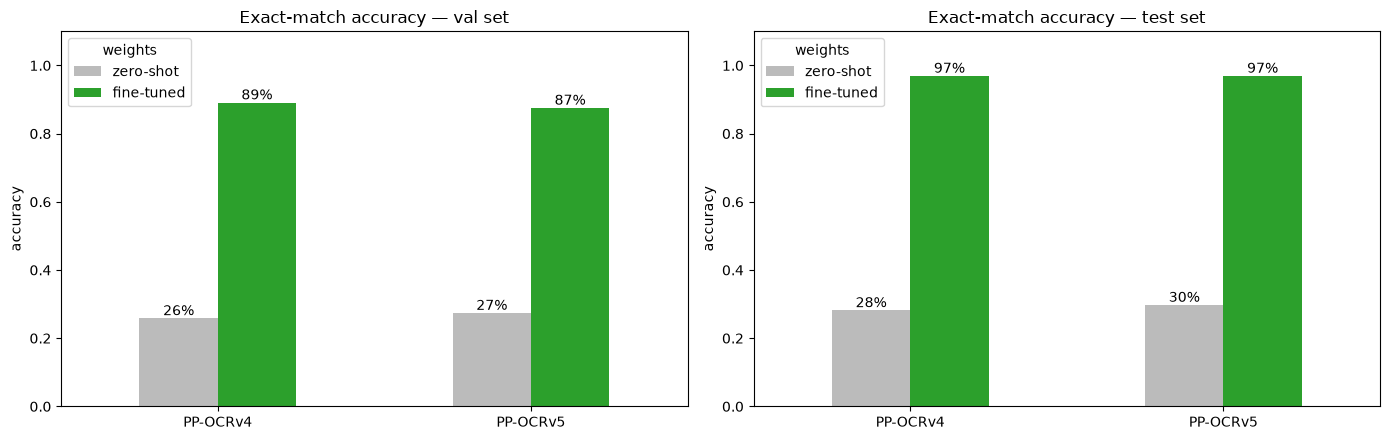

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, split in zip(axes, ("val", "test")):
    sub = eval_df[eval_df.split == split].pivot(index="model", columns="weights", values="acc")[["zero-shot", "fine-tuned"]]
    sub.plot.bar(ax=ax, rot=0, color=["#bbbbbb", "#2ca02c"])
    for container in ax.containers:
        ax.bar_label(container, fmt=lambda v: f"{v:.0%}")
    ax.set(title=f"Exact-match accuracy — {split} set", ylim=(0, 1.1), ylabel="accuracy", xlabel="")
plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "zero_shot_vs_finetuned.png"), dpi=120)
plt.show()

## 9. Export to inference format
`tools/export_model.py` converts the best training checkpoint into a static inference model (`inference.json`, `inference.pdiparams` and `inference.yml`).
The `paddleocr` Python API loads this format, and the inference notebook uses it.

In [18]:
for key, m in MODELS.items():
    best_ckpt = os.path.join(m["save_dir"], "best_accuracy")
    assert os.path.exists(best_ckpt + ".pdparams"), f"missing {best_ckpt}.pdparams — did training finish?"
    run([sys.executable, "tools/export_model.py", "-c", m["config"], "-o",
         f"Global.pretrained_model={best_ckpt}", f"Global.save_inference_dir={m['inference_dir']}"],
        os.path.join(RESULTS_DIR, f"{m['name']}_export.log"), show=lambda line: "Error" in line)
    files = {f: os.path.getsize(os.path.join(m["inference_dir"], f)) for f in sorted(os.listdir(m["inference_dir"]))}
    m["size_mb"] = sum(files.values()) / 1e6
    print(f"{key}: {m['inference_dir']}")
    for f, size in files.items():
        print(f"   {f:22s} {size / 1e6:8.1f} MB")

$ ..\..\.venv\Scripts\python.exe tools/export_model.py -c ..\configs\PP-OCRv5_server_rec_license_plate.yml -o Global.pretrained_model=C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\work\output\PP-OCRv5_server_rec\best_accuracy Global.save_inference_dir=C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\work\inference\PP-OCRv5_server_rec


PP-OCRv5: C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\work\inference\PP-OCRv5_server_rec
   inference.json              0.3 MB
   inference.pdiparams        84.4 MB
   inference.yml               0.2 MB
$ ..\..\.venv\Scripts\python.exe tools/export_model.py -c ..\configs\PP-OCRv4_server_rec_license_plate.yml -o Global.pretrained_model=C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\work\output\PP-OCRv4_server_rec\best_accuracy Global.save_inference_dir=C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\work\inference\PP-OCRv4_server_rec


PP-OCRv4: C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\work\inference\PP-OCRv4_server_rec
   inference.json              0.2 MB
   inference.pdiparams        90.5 MB
   inference.yml               0.1 MB


### 9.1 Check the exported models
Load each exported model with the `paddleocr` API, read every held-out test plate, and time each prediction. This confirms the exported files work outside the training code.

C:\Users\ritesh-18\Desktop\ritesh\benchmarking-tool\lynkit\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


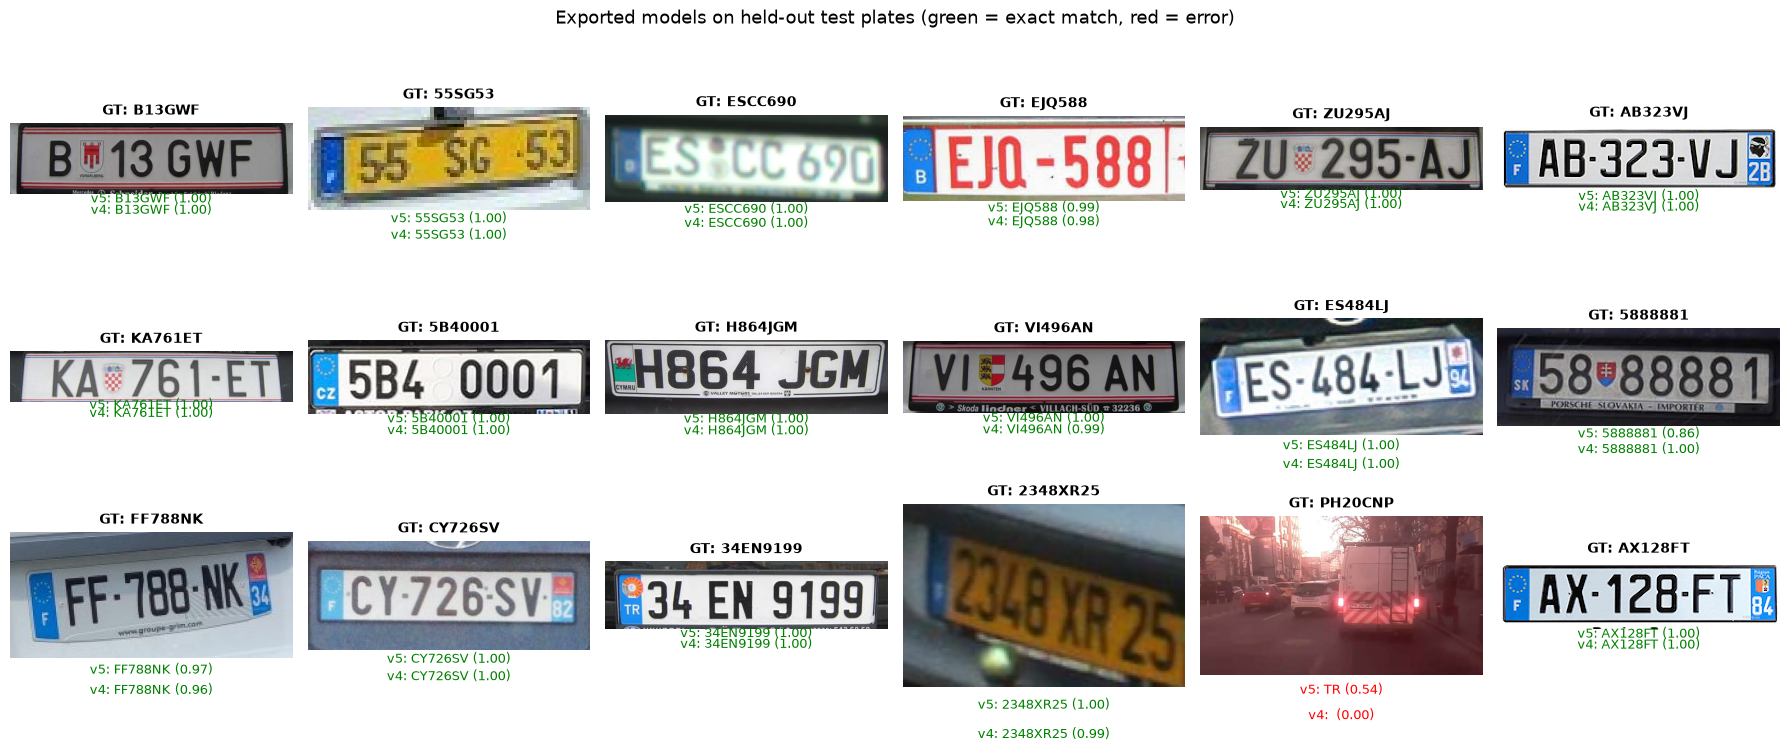

In [19]:
from paddleocr import TextRecognition

def levenshtein(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

pred_rows = []
for key, m in MODELS.items():
    recognizer = TextRecognition(model_name=m["name"], model_dir=m["inference_dir"])
    recognizer.predict(input=os.path.join(PLATES_ROOT, test_items[0][0]))  # warm-up
    for img, label in test_items:
        start = time.perf_counter()
        res = recognizer.predict(input=os.path.join(PLATES_ROOT, img))[0].json["res"]
        ms = (time.perf_counter() - start) * 1000
        pred = res["rec_text"].replace(" ", "")
        pred_rows.append({"model": key, "image": img, "label": label, "pred": pred, "score": float(res["rec_score"]),
                          "correct": pred == label, "cer": levenshtein(pred, label) / len(label), "ms": ms})
pred_df = pd.DataFrame(pred_rows)
pred_df.to_csv(os.path.join(RESULTS_DIR, "test_predictions.csv"), index=False)

sample = random.Random(SEED).sample(test_items, 18)
wide = pred_df.set_index(["image", "model"])
fig, axes = plt.subplots(3, 6, figsize=(18, 7.5))
for ax, (img, label) in zip(axes.flat, sample):
    ax.imshow(Image.open(os.path.join(PLATES_ROOT, img)).convert("RGB"))
    ax.set_title(f"GT: {label}", fontsize=10, fontweight="bold")
    for i, key in enumerate(MODELS):
        r = wide.loc[(img, key)]
        ax.text(0.5, -0.12 - 0.16 * i, f"{key[-2:]}: {r.pred} ({r.score:.2f})", transform=ax.transAxes,
                ha="center", fontsize=9, color="green" if r.correct else "red")
    ax.axis("off")
fig.suptitle("Exported models on held-out test plates (green = exact match, red = error)", fontsize=13)
plt.tight_layout()
plt.show()

## 10. Comparison and summary
The table combines training time, validation and test accuracy, character accuracy, latency, and exported model size for each model.

,training time (min),best val accuracy,test accuracy (zero-shot),test accuracy (fine-tuned),test char accuracy,mean confidence,"latency (ms/plate, median)",model size (MB)
model,,,,,,,,
PP-OCRv5_server_rec,7.4,87.5%,29.7%,96.9%,98.1%,98.4%,10.2,84.9
PP-OCRv4_server_rec,15.2,89.1%,28.1%,96.9%,98.1%,97.9%,10.6,90.7


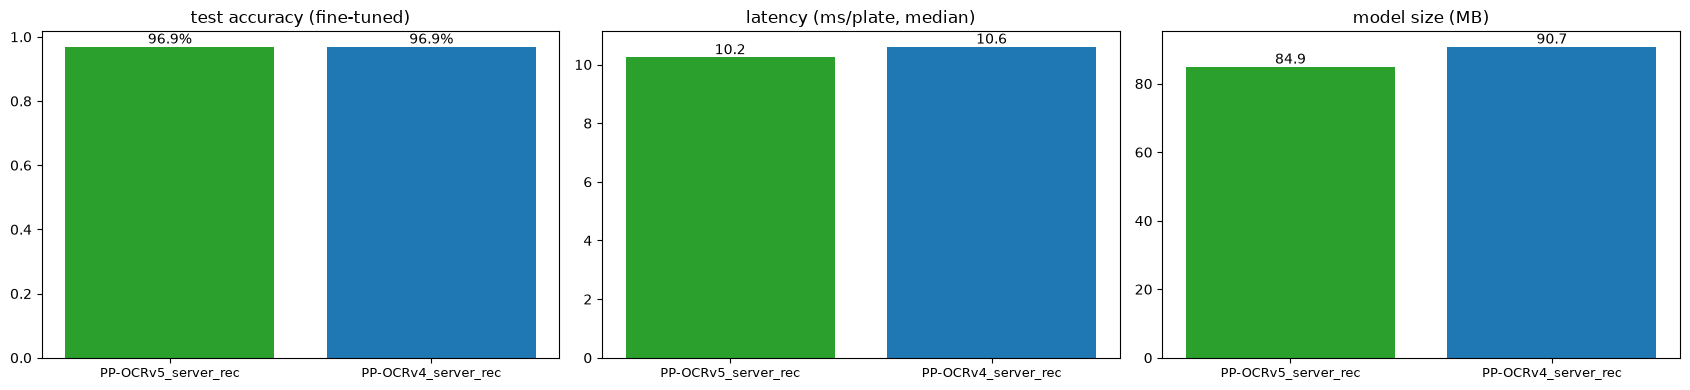

Summary
- PP-OCRv5_server_rec: test accuracy 29.7% (zero-shot) → 96.9% (fine-tuned), character accuracy 98.1%, 10.2 ms/plate, 85 MB
- PP-OCRv4_server_rec: test accuracy 28.1% (zero-shot) → 96.9% (fine-tuned), character accuracy 98.1%, 10.6 ms/plate, 91 MB
- After fine-tuning, PP-OCRv5 is 0.0% more accurate than PP-OCRv4 on the 67 held-out test plates.


In [20]:
summary_rows = []
for key, m in MODELS.items():
    _, ev = curves[key]
    p = pred_df[pred_df.model == key]
    acc = eval_df.set_index(["model", "weights", "split"])["acc"]
    summary_rows.append({
        "model": m["name"],
        "training time (min)": m["train_minutes"],
        "best val accuracy": ev["acc"].max(),
        "test accuracy (zero-shot)": acc[(key, "zero-shot", "test")],
        "test accuracy (fine-tuned)": acc[(key, "fine-tuned", "test")],
        "test char accuracy": 1 - p["cer"].mean(),
        "mean confidence": p["score"].mean(),
        "latency (ms/plate, median)": p["ms"].median(),
        "model size (MB)": m["size_mb"],
    })
summary_df = pd.DataFrame(summary_rows).set_index("model")
summary_df.to_csv(os.path.join(RESULTS_DIR, "model_comparison.csv"))
pct = [c for c in summary_df.columns if "accuracy" in c or "confidence" in c]
display(summary_df.style.format("{:.1%}", subset=pct).format("{:.1f}", subset=[c for c in summary_df.columns if c not in pct]))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
colors = ["#2ca02c", "#1f77b4"]
for ax, col in zip(axes, ["test accuracy (fine-tuned)", "latency (ms/plate, median)", "model size (MB)"]):
    bars = ax.bar(summary_df.index, summary_df[col], color=colors)
    ax.bar_label(bars, fmt=lambda v: f"{v:.1%}" if "accuracy" in col else f"{v:.1f}")
    ax.set_title(col)
    ax.tick_params(axis="x", labelsize=9)
plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "model_comparison.png"), dpi=120)
plt.show()

v5, v4 = summary_df.iloc[0], summary_df.iloc[1]
print("Summary")
for name, r in summary_df.iterrows():
    print(f"- {name}: test accuracy {r['test accuracy (zero-shot)']:.1%} (zero-shot) → {r['test accuracy (fine-tuned)']:.1%} "
          f"(fine-tuned), character accuracy {r['test char accuracy']:.1%}, "
          f"{r['latency (ms/plate, median)']:.1f} ms/plate, {r['model size (MB)']:.0f} MB")
diff = v5["test accuracy (fine-tuned)"] - v4["test accuracy (fine-tuned)"]
print(f"- After fine-tuning, PP-OCRv5 is {abs(diff):.1%} {'more' if diff >= 0 else 'less'} accurate than PP-OCRv4 "
      f"on the {len(test_items)} held-out test plates.")

## 11. Save artifacts
The following are copied to `MyDrive/ppocr_license_plate/` for the inference notebook and for the submission:
- the exported inference models
- the configs
- logs, CSVs and plots
- the held-out test images with their labels

In [21]:
for m in MODELS.values():
    shutil.copytree(m["inference_dir"], os.path.join(ARTIFACT_DIR, "inference", m["name"]), dirs_exist_ok=True)
shutil.copytree(CONFIG_DIR, os.path.join(ARTIFACT_DIR, "configs"), dirs_exist_ok=True)
shutil.copytree(RESULTS_DIR, os.path.join(ARTIFACT_DIR, "results"), dirs_exist_ok=True)

test_dir = os.path.join(ARTIFACT_DIR, "test_data")
os.makedirs(os.path.join(test_dir, "test"), exist_ok=True)
for img, _ in test_items:
    shutil.copy2(os.path.join(PLATES_ROOT, img), os.path.join(test_dir, img))
for name in ("train", "val", "test"):
    shutil.copy2(LABEL_FILES[name], os.path.join(test_dir, f"{name}.txt"))

for root, dirs, files in os.walk(ARTIFACT_DIR):
    depth = root[len(ARTIFACT_DIR):].count(os.sep)
    if depth <= 2:
        print("  " * depth + os.path.basename(root) + f"/  ({len(files)} files)")

artifacts/  (0 files)
  configs/  (2 files)
  inference/  (0 files)
    PP-OCRv4_server_rec/  (3 files)
    PP-OCRv5_server_rec/  (3 files)
  results/  (19 files)
  test_data/  (3 files)
    test/  (67 files)


## 12. Findings
*Run on a local NVIDIA RTX 3050 Laptop GPU (6 GB), 40 epochs per model, batch size 32, learning rate 5e-5.*

| | PP-OCRv5_server_rec | PP-OCRv4_server_rec |
|---|---|---|
| Test accuracy, zero-shot → fine-tuned (`eval.py`) | 29.7% → **96.9%** | 28.1% → **96.9%** |
| Test accuracy, exported model, all 67 plates (9.1) | **95.5%** (64/67) | **95.5%** (64/67) |
| Test character accuracy | 98.1% | 98.1% |
| Best validation accuracy | 87.5% (epoch 12) | 89.1% (epoch 12) |
| Training time (40 epochs) | 7.4 min | 15.2 min |
| Latency per plate crop (median) | 10.2 ms | 10.6 ms |
| Exported model size | 85 MB | 91 MB |

**1. Fine-tuning is what makes these models usable for plates.** Out of the box, both models read under 30% of test plates exactly. After fine-tuning on 530 plates, both read about 96%, and normalized edit distance rises from 0.84 to 0.98. About half the zero-shot gap is formatting: when their output is reduced to `A–Z0–9` (inference notebook, section 6), the official models score 76–79%. They have learned to read text, but not plate conventions such as which separators and symbols to skip.

**2. PP-OCRv5 and PP-OCRv4 are tied on accuracy.** Both get the same 64 of 67 test plates right, and their 3 errors are on the same 3 plates. PP-OCRv4 has a slightly higher best validation score (89.1% vs 87.5%, a difference of 2 of 128 images) and a smoother validation curve. PP-OCRv5 reaches about 100% training accuracy sooner and its validation score fluctuates more, so it is the quicker of the two to overfit a small dataset.

**3. Learning rate matters more than model version here.** A first run at 2e-4 overfit: training accuracy reached 100% while validation accuracy fell from 86% to about 80%. Lowering the rate to 5e-5 fixed this for both models.

**4. Speed and size slightly favour PP-OCRv5.** It is about 7% smaller and marginally faster per crop. With equal accuracy, PP-OCRv5 is the better choice to deploy.

**Evaluation note.** PaddleOCR's `eval.py` scored 128 of the 132 validation images and 64 of the 67 test images; the accuracy values are exactly 110/128 and 62/64. It appears to skip the final incomplete batch. The exported-model check in section 9.1 covers every test image, so 95.5% is the more complete test figure.

**Limitations.** The dataset is small: 67 test plates, so one plate is 1.5%. The plates come from a handful of European countries and are cleanly cropped. The inference notebook tests the models on full car photos from a different source.